<a href="https://colab.research.google.com/github/Ritapaz/redes-neurais/blob/main/Previsao_consumo_energia_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q openpyxl tensorflow scikit-learn

Selecione o arquivo Excel com os dados da EPE.


Saving Consumo de energia.xlsx to Consumo de energia.xlsx

Colunas encontradas:
['Data', 'Consumo MWh']

BASE ORGANIZADA
             Consumo_GWh
Data                    
2004-01-01  26978.361463
2004-02-01  26508.269295
2004-03-01  27284.337172
2004-04-01  28046.181323
2004-05-01  27248.156753

Últimas observações:
             Consumo_GWh
Data                    
2026-03-01  48937.203723
2026-04-01  49635.166888
2026-05-01  48034.965326
2026-06-01  46203.188624
2026-07-01  46840.979536

Número de meses: 271
Período: 01/2004 a 07/2026


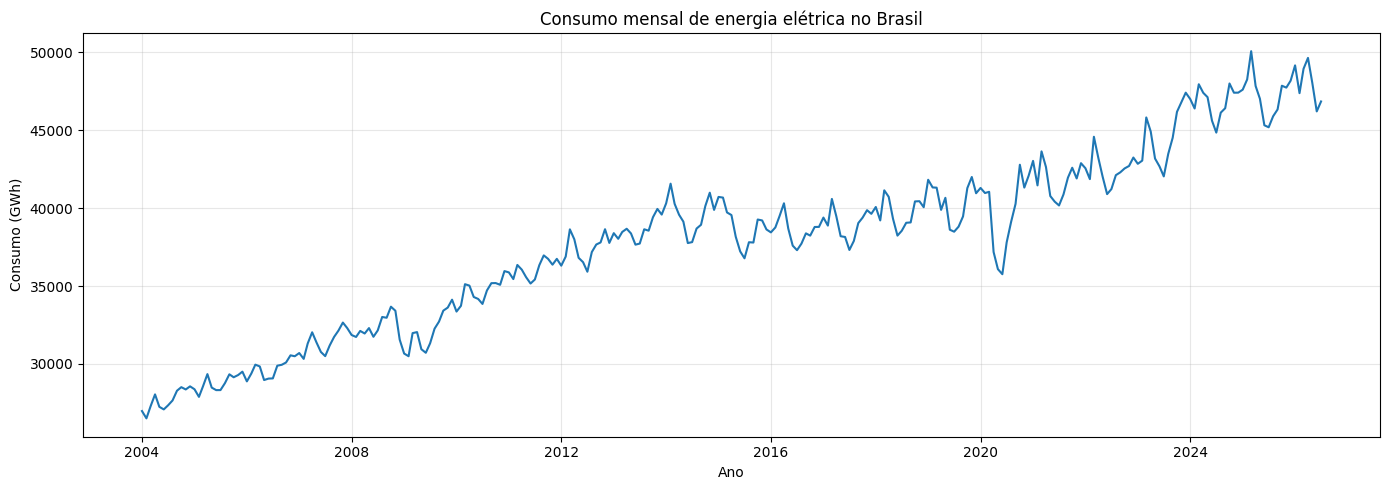


DIVISÃO DA BASE
Treinamento: 01/2004 até 09/2019
Validação: 10/2019 até 02/2023
Teste: 03/2023 até 07/2026

MODELO LSTM - 1 MÊS(ES)

Amostras de treinamento: 165
Amostras de validação: 41
Amostras de teste: 41
Épocas executadas: 27

MÉTRICAS DE TESTE
MAE: 3525.7302
MSE: 14477289.0000
RMSE: 3804.9033
MAPE (%): 7.4635
sMAPE (%): 7.7986
R2: -3.6408

PREVISÃO FUTURA
Data: 08/2026
Consumo previsto: 44,010.38 GWh

MODELO LSTM - 3 MÊS(ES)

Amostras de treinamento: 163
Amostras de validação: 41
Amostras de teste: 41
Épocas executadas: 21

MÉTRICAS DE TESTE
MAE: 2787.2778
MSE: 9642202.0000
RMSE: 3105.1895
MAPE (%): 5.8921
sMAPE (%): 6.1129
R2: -2.0909

PREVISÃO FUTURA
Data: 10/2026
Consumo previsto: 45,165.34 GWh

MODELO LSTM - 6 MÊS(ES)

Amostras de treinamento: 160
Amostras de validação: 41
Amostras de teste: 41


Épocas executadas: 30



MÉTRICAS DE TESTE
MAE: 3930.8506
MSE: 17598160.0000
RMSE: 4195.0161
MAPE (%): 8.3266
sMAPE (%): 8.7362
R2: -4.6412

PREVISÃO FUTURA
Data: 01/2027
Consumo previsto: 43,586.54 GWh

MODELO LSTM - 12 MÊS(ES)

Amostras de treinamento: 154
Amostras de validação: 41
Amostras de teste: 41
Épocas executadas: 24

MÉTRICAS DE TESTE
MAE: 4109.2090
MSE: 19157260.0000
RMSE: 4376.9007
MAPE (%): 8.7101
sMAPE (%): 9.1579
R2: -5.1410

PREVISÃO FUTURA
Data: 07/2027
Consumo previsto: 43,881.51 GWh

COMPARAÇÃO DOS MODELOS LSTM


,MAE,MSE,RMSE,MAPE (%),sMAPE (%),R2
Horizonte,,,,,,
1 mês(es),3525.7302,14477289.0,3804.9033,7.4635,7.7986,-3.6408
3 mês(es),2787.2778,9642202.0,3105.1895,5.8921,6.1129,-2.0909
6 mês(es),3930.8506,17598160.0,4195.0161,8.3266,8.7362,-4.6412
12 mês(es),4109.2090,19157260.0,4376.9007,8.7101,9.1579,-5.1410



PREVISÕES FUTURAS


,Horizonte_meses,Data,Consumo_previsto_GWh,Consumo_previsto_MWh
0,1,2026-08-01,44010.378906,44010384.0
1,3,2026-10-01,45165.339844,45165344.0
2,6,2027-01-01,43586.539062,43586540.0
3,12,2027-07-01,43881.511719,43881508.0


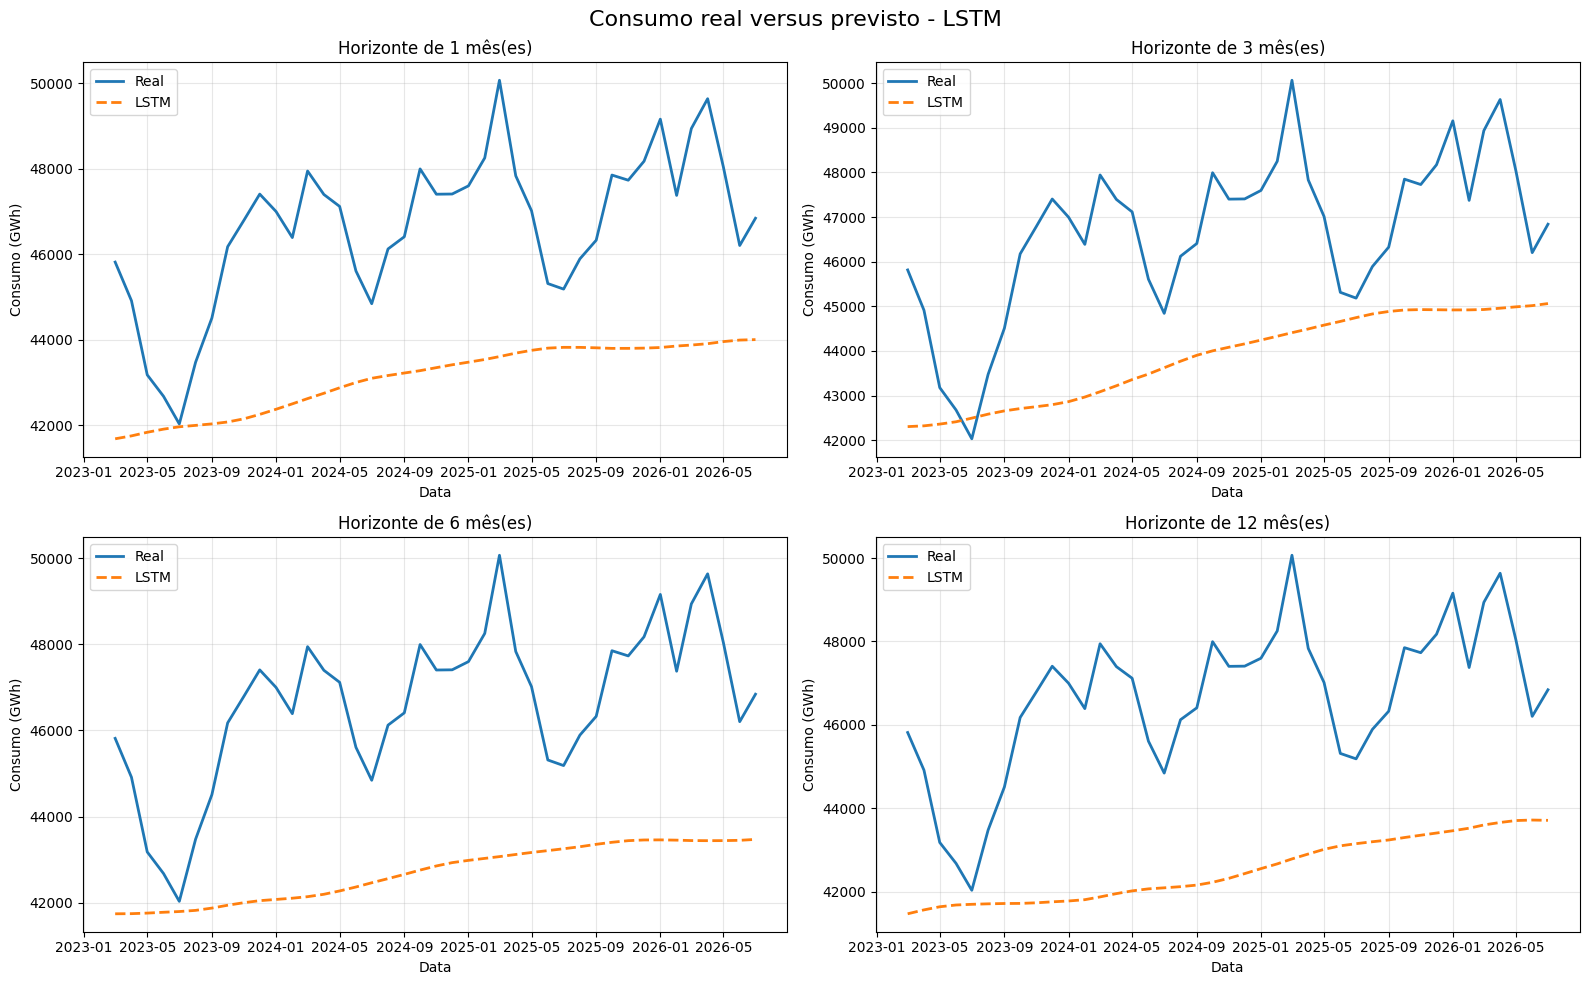

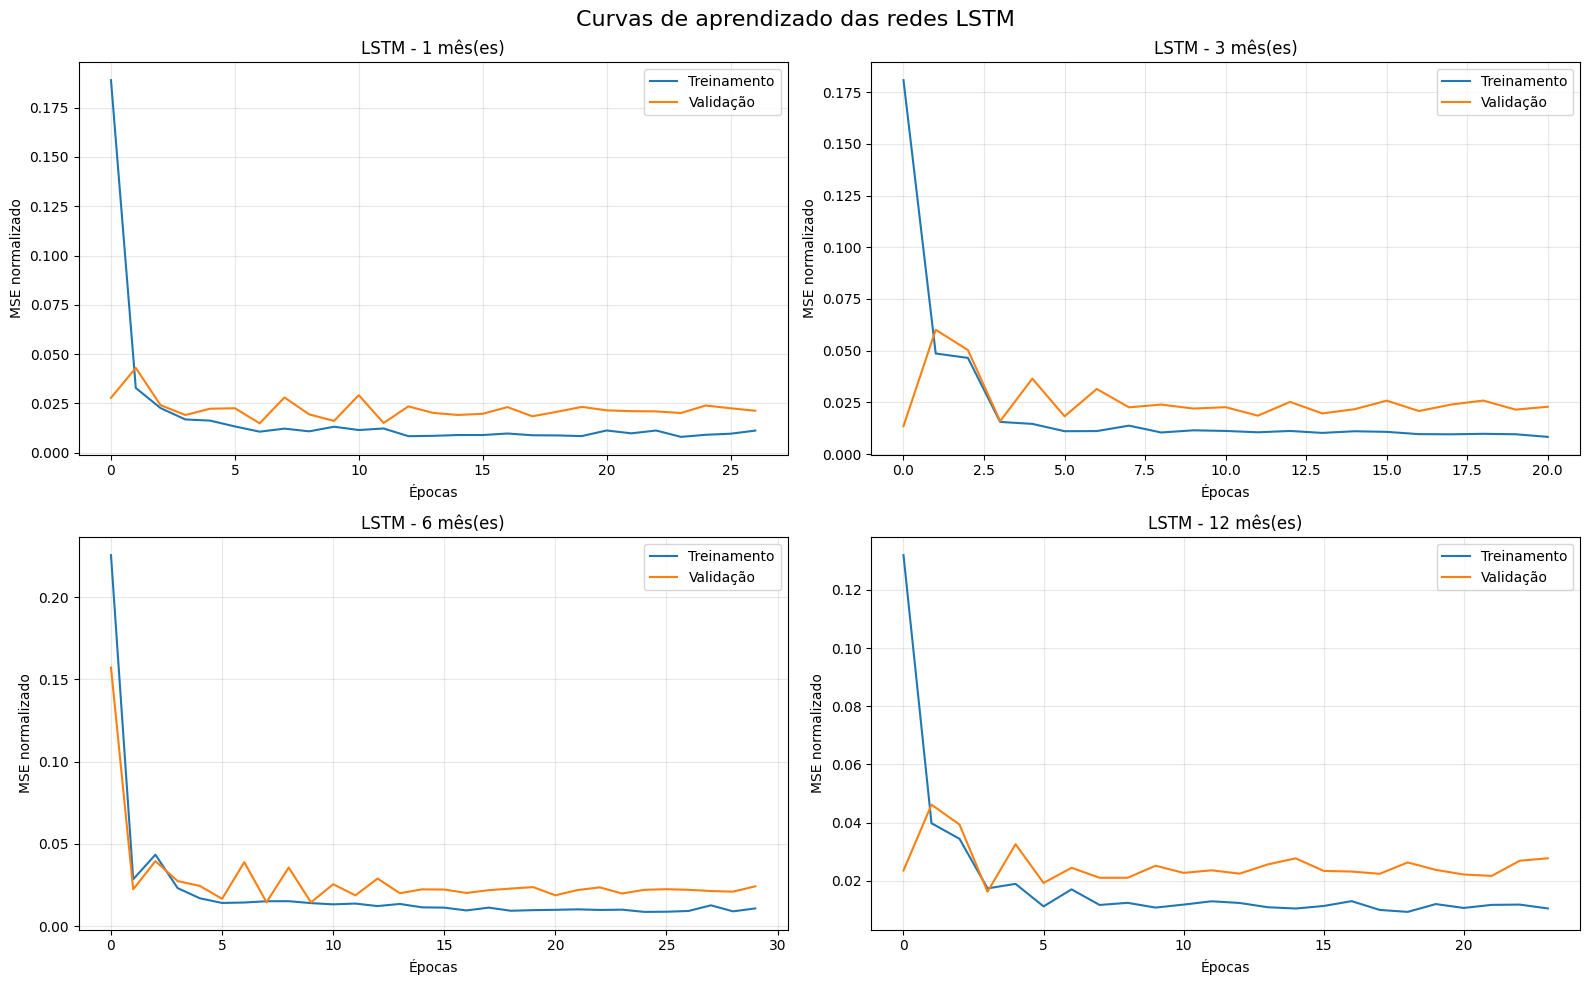

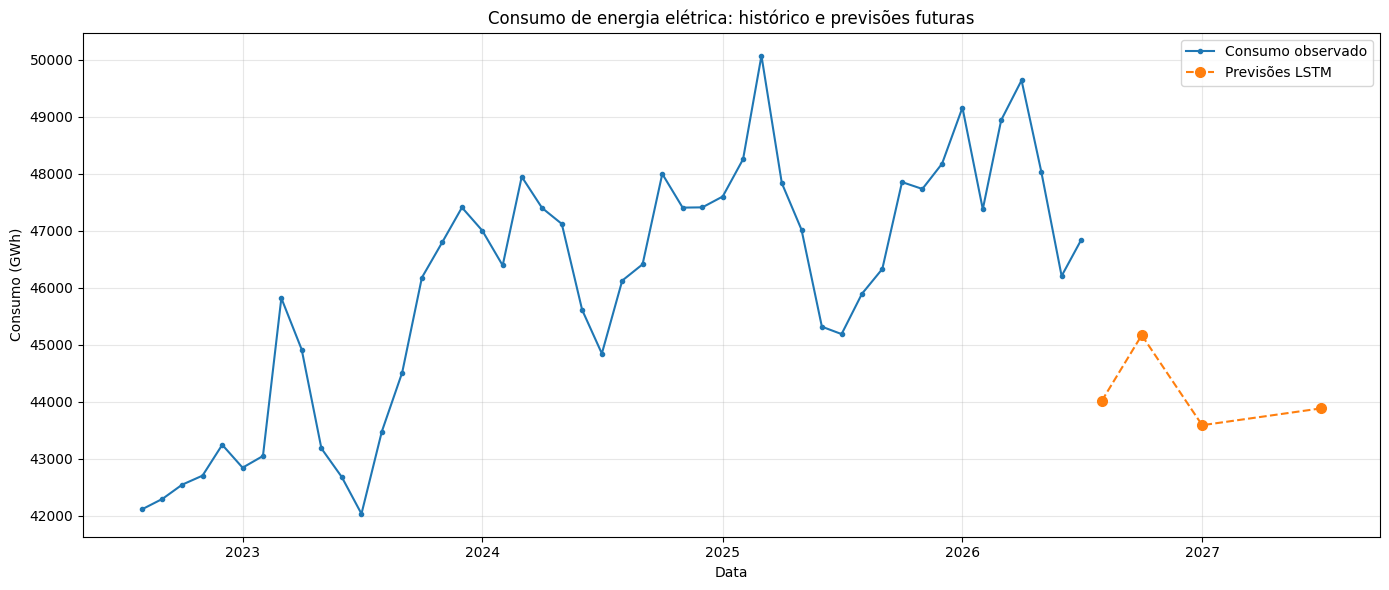


Arquivo Excel gerado:
/content/resultados_lstm/resultados_lstm_energia.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Processamento concluído.


In [ ]:

# ============================================================
# PREVISÃO DO CONSUMO DE ENERGIA ELÉTRICA COM LSTM
# Horizontes: 1, 3, 6 e 12 meses
# Base: EPE - Consumo mensal de energia elétrica
# Ambiente: Google Colab
# ============================================================

import os
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from google.colab import files

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

from sklearn.preprocessing import MinMaxScaler

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
)

from tensorflow.keras.layers import (
    Input,
    LSTM,
    Dense,
    Dropout,
)

from tensorflow.keras.models import Sequential


# ============================================================
# 1. CONFIGURAÇÕES
# ============================================================

SEMENTE = 42

random.seed(SEMENTE)
np.random.seed(SEMENTE)
tf.keras.utils.set_random_seed(SEMENTE)

LOOKBACK = 24    # janelas de 24 meses

HORIZONTES = [1, 3, 6, 12]

EPOCAS = 200
BATCH_SIZE = 16

TAXA_APRENDIZADO = 0.001

PROPORCAO_TREINO = 0.70
PROPORCAO_VALIDACAO = 0.15

UNIDADE = "GWh"

PASTA_RESULTADOS = "/content/resultados_lstm"

os.makedirs(
    PASTA_RESULTADOS,
    exist_ok=True,
)


# ============================================================
# 2. IMPORTAÇÃO DO EXCEL
# ============================================================

print("Selecione o arquivo Excel com os dados da EPE.")

arquivos = files.upload()

nome_arquivo = next(iter(arquivos))

df = pd.read_excel(
    nome_arquivo,
    sheet_name=0,
)

print("\nColunas encontradas:")

print(df.columns.tolist())

# Considera as duas primeiras colunas da planilha:
# primeira = data
# segunda = consumo em MWh

# --- Início da modificação ---
if len(df.columns) == 1:
    # Assuming the single column is Consumo_MWh and Data needs to be generated
    df.columns = ["Consumo_MWh"]
    # Generate a 'Data' column with monthly frequency, starting from an arbitrary date.
    # User should adjust the start_date if their data has a specific beginning.
    start_date = pd.to_datetime('1990-01-01') # Placeholder: Adjust if necessary
    df['Data'] = pd.date_range(start=start_date, periods=len(df), freq='MS')
    # Reorder columns to have 'Data' first
    df = df[['Data', 'Consumo_MWh']]
elif len(df.columns) >= 2:
    df = df.iloc[:, :2].copy()
    df.columns = [
        "Data",
        "Consumo_MWh",
    ]
else:
    raise ValueError("O arquivo Excel enviado deve conter pelo menos uma coluna com dados de consumo.")
# --- Fim da modificação ---


# ============================================================
# 3. TRATAMENTO DOS DADOS
# ============================================================

df["Data"] = pd.to_datetime(
    df["Data"],
    dayfirst=True,
    errors="coerce",
)

# Conversão numérica.
# Aceita números do Excel ou valores textuais no padrão
# brasileiro, como 45.000.000,50.

consumo_numerico = pd.to_numeric(
    df["Consumo_MWh"],
    errors="coerce",
)

if consumo_numerico.isna().any():

    consumo_texto = (
        df["Consumo_MWh"]
        .astype(str)
        .str.strip()
        .str.replace(".", "", regex=False)
        .str.replace(",", ".", regex=False)
    )

    consumo_numerico = pd.to_numeric(
        consumo_texto,
        errors="coerce",
    )

df["Consumo_MWh"] = consumo_numerico

# Verificação de valores inválidos.

if df.isna().any().any():

    raise ValueError(
        "A planilha contém datas ou valores inválidos."
    )

if (df["Consumo_MWh"] < 0).any():

    raise ValueError(
        "Foram encontrados valores negativos de consumo."
    )

# Padronização das datas para o primeiro dia do mês.

df["Data"] = (
    df["Data"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

if df["Data"].duplicated().any():

    raise ValueError(
        "Existem meses duplicados na planilha."
    )

df = df.sort_values("Data")

df = df.set_index("Data")

# Garantir frequência mensal.

df = df.asfreq("MS")

if df["Consumo_MWh"].isna().any():

    raise ValueError(
        "Existem meses sem observações. "
        "Verifique a série histórica."
    )

# ------------------------------------------------------------
# CONVERSÃO DE MWh PARA GWh
# ------------------------------------------------------------

df["Consumo_GWh"] = (
    df["Consumo_MWh"] / 1000
)

serie = df[["Consumo_GWh"]].copy()

print("\nBASE ORGANIZADA")

print(serie.head())

print("\nÚltimas observações:")

print(serie.tail())

print("\nNúmero de meses:", len(serie))

print(
    "Período:",
    serie.index.min().strftime("%m/%Y"),
    "a",
    serie.index.max().strftime("%m/%Y"),
)


# ============================================================
# 4. VISUALIZAÇÃO DA SÉRIE HISTÓRICA
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    serie.index,
    serie["Consumo_GWh"],
    linewidth=1.5,
)

plt.title(
    "Consumo mensal de energia elétrica no Brasil"
)

plt.xlabel("Ano")

plt.ylabel("Consumo (GWh)")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ============================================================
# 5. DIVISÃO TEMPORAL
# ============================================================

valores = serie.values

n = len(valores)

limite_treino = int(
    n * PROPORCAO_TREINO
)

limite_validacao = int(
    n * (
        PROPORCAO_TREINO
        + PROPORCAO_VALIDACAO
    )
)

print("\nDIVISÃO DA BASE")

print(
    "Treinamento:",
    serie.index[0].strftime("%m/%Y"),
    "até",
    serie.index[
        limite_treino - 1
    ].strftime("%m/%Y"),
)

print(
    "Validação:",
    serie.index[
        limite_treino
    ].strftime("%m/%Y"),
    "até",
    serie.index[
        limite_validacao - 1
    ].strftime("%m/%Y"),
)

print(
    "Teste:",
    serie.index[
        limite_validacao
    ].strftime("%m/%Y"),
    "até",
    serie.index[-1].strftime("%m/%Y"),
)


# ============================================================
# 6. NORMALIZAÇÃO
# ============================================================

scaler = MinMaxScaler(
    feature_range=(0, 1)
)

# Ajusta o scaler somente com o treinamento.
# Evita vazamento de informações futuras.

scaler.fit(
    valores[:limite_treino]
)

valores_normalizados = (
    scaler.transform(valores)
    .flatten()
)


# ============================================================
# 7. CRIAÇÃO DAS SEQUÊNCIAS
# ============================================================

def criar_sequencias(
    dados,
    lookback,
    horizonte,
):
    """
    Cria sequências para previsão direta.

    Entrada:
        24 observações anteriores.

    Saída:
        consumo no horizonte escolhido.
    """

    X = []
    y = []
    indices = []

    for origem in range(
        lookback,
        len(dados) - horizonte + 1,
    ):

        inicio = origem - lookback

        fim = origem

        alvo = origem + horizonte - 1

        X.append(
            dados[inicio:fim]
        )

        y.append(
            dados[alvo]
        )

        indices.append(
            alvo
        )

    X = np.array(
        X,
        dtype=np.float32,
    )

    y = np.array(
        y,
        dtype=np.float32,
    )

    X = X.reshape(
        -1,
        lookback,
        1,
    )

    y = y.reshape(-1, 1)

    return (
        X,
        y,
        np.array(indices),
    )


# ============================================================
# 8. ARQUITETURA LSTM
# ============================================================

def construir_lstm():

    modelo = Sequential(
        [
            Input(
                shape=(LOOKBACK, 1)
            ),

            LSTM(
                64,
                return_sequences=True,
                activation="tanh",
            ),

            Dropout(0.20),

            LSTM(
                32,
                activation="tanh",
            ),

            Dropout(0.20),

            Dense(
                16,
                activation="relu",
            ),

            Dense(
                1,
                activation="linear",
            ),
        ]
    )

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=TAXA_APRENDIZADO
        ),

        loss="mse",

        metrics=["mae"],
    )

    return modelo


# ============================================================
# 9. MÉTRICAS DE AVALIAÇÃO
# ============================================================

def calcular_metricas(
    real,
    previsto,
):

    real = np.asarray(
        real
    ).flatten()

    previsto = np.asarray(
        previsto
    ).flatten()

    mae = mean_absolute_error(
        real,
        previsto,
    )

    mse = mean_squared_error(
        real,
        previsto,
    )

    rmse = np.sqrt(mse)

    erro = np.abs(
        real - previsto
    )

    # MAPE

    mascara = real != 0

    if mascara.any():

        mape = np.mean(
            erro[mascara]
            / np.abs(real[mascara])
        ) * 100

    else:

        mape = np.nan

    # sMAPE

    denominador = (
        np.abs(real)
        + np.abs(previsto)
    )

    smape = np.mean(
        np.divide(
            2 * erro,
            denominador,
            out=np.zeros_like(
                erro,
                dtype=float,
            ),
            where=denominador != 0,
        )
    ) * 100

    # Coeficiente de determinação

    r2 = r2_score(
        real,
        previsto,
    )

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "sMAPE (%)": smape,
        "R2": r2,
    }


# ============================================================
# 10. TREINAMENTO DOS QUATRO MODELOS
# ============================================================

resultados = []

previsoes_futuras = []

previsoes_teste = {}

historicos = {}

modelos = {}

for horizonte in HORIZONTES:

    print("\n" + "=" * 60)

    print(
        f"MODELO LSTM - {horizonte} MÊS(ES)"
    )

    print("=" * 60)

    tf.keras.backend.clear_session()

    # --------------------------------------------------------
    # Criar sequências para o horizonte atual
    # --------------------------------------------------------

    X, y, indices = criar_sequencias(
        valores_normalizados,
        LOOKBACK,
        horizonte,
    )

    # Separação pelo índice da variável-alvo.

    mascara_treino = (
        indices < limite_treino
    )

    mascara_validacao = (
        (indices >= limite_treino)
        & (indices < limite_validacao)
    )

    mascara_teste = (
        indices >= limite_validacao
    )

    X_treino = X[mascara_treino]

    y_treino = y[mascara_treino]

    X_validacao = X[mascara_validacao]

    y_validacao = y[mascara_validacao]

    X_teste = X[mascara_teste]

    y_teste = y[mascara_teste]

    print(
        "\nAmostras de treinamento:",
        len(X_treino),
    )

    print(
        "Amostras de validação:",
        len(X_validacao),
    )

    print(
        "Amostras de teste:",
        len(X_teste),
    )

    # --------------------------------------------------------
    # Construir modelo
    # --------------------------------------------------------

    modelo = construir_lstm()

    callbacks = [

        EarlyStopping(
            monitor="val_loss",
            patience=20,
            restore_best_weights=True,
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=8,
            min_lr=0.00001,
        ),
    ]

    # --------------------------------------------------------
    # Treinar LSTM
    # --------------------------------------------------------

    historico = modelo.fit(
        X_treino,
        y_treino,

        validation_data=(
            X_validacao,
            y_validacao,
        ),

        epochs=EPOCAS,

        batch_size=BATCH_SIZE,

        callbacks=callbacks,

        shuffle=False,

        verbose=0,
    )

    historicos[horizonte] = historico

    modelos[horizonte] = modelo

    print(
        "Épocas executadas:",
        len(historico.history["loss"]),
    )

    # --------------------------------------------------------
    # Previsão no conjunto de teste
    # --------------------------------------------------------

    y_previsto_norm = modelo.predict(
        X_teste,
        verbose=0,
    )

    y_previsto = (
        scaler.inverse_transform(
            y_previsto_norm
        )
        .flatten()
    )

    y_real = (
        scaler.inverse_transform(
            y_teste
        )
        .flatten()
    )

    # --------------------------------------------------------
    # Calcular métricas
    # --------------------------------------------------------

    metricas = calcular_metricas(
        y_real,
        y_previsto,
    )

    metricas["Horizonte"] = (
        f"{horizonte} mês(es)"
    )

    resultados.append(metricas)

    print("\nMÉTRICAS DE TESTE")

    for chave, valor in metricas.items():

        if chave != "Horizonte":

            print(
                f"{chave}: {valor:.4f}"
            )

    # --------------------------------------------------------
    # Guardar resultados históricos
    # --------------------------------------------------------

    datas_teste = serie.index[
        indices[mascara_teste]
    ]

    df_teste = pd.DataFrame(
        {
            "Real_GWh": y_real,

            "Previsto_GWh": y_previsto,

            "Erro_GWh": (
                y_real - y_previsto
            ),
        },

        index=datas_teste,
    )

    df_teste.index.name = "Data"

    previsoes_teste[horizonte] = df_teste

    # --------------------------------------------------------
    # PREVISÃO FUTURA
# --------------------------------------------------------

    ultima_janela = (
        valores_normalizados[-LOOKBACK:]
        .reshape(1, LOOKBACK, 1)
    )

    previsao_norm = modelo.predict(
        ultima_janela,
        verbose=0,
    )

    consumo_futuro = (
        scaler.inverse_transform(
            previsao_norm
        )[0, 0]
    )

    ultima_data = serie.index[-1]

    data_futura = (
        ultima_data
        + pd.DateOffset(
            months=horizonte
        )
    )

    previsoes_futuras.append(
        {
            "Horizonte_meses": horizonte,

            "Data": data_futura,

            "Consumo_previsto_GWh": consumo_futuro,

            "Consumo_previsto_MWh": (
                consumo_futuro * 1000
            ),
        }
    )

    print("\nPREVISÃO FUTURA")

    print(
        "Data:",
        data_futura.strftime("%m/%Y"),
    )

    print(
        f"Consumo previsto: "
        f"{consumo_futuro:,.2f} GWh"
    )

    # --------------------------------------------------------
    # Salvar modelo
    # --------------------------------------------------------

    modelo.save(
        os.path.join(
            PASTA_RESULTADOS,
            f"lstm_{horizonte}_meses.keras",
        )
    )


# ============================================================
# 11. TABELA COMPARATIVA
# ============================================================

df_metricas = pd.DataFrame(
    resultados
)

df_metricas = df_metricas.set_index(
    "Horizonte"
)

print("\n" + "=" * 60)

print("COMPARAÇÃO DOS MODELOS LSTM")

print("=" * 60)

display(
    df_metricas.round(4)
)


# ============================================================
# 12. TABELA DE PREVISÕES FUTURAS
# ============================================================

df_futuro = pd.DataFrame(
    previsoes_futuras
)

print("\nPREVISÕES FUTURAS")

display(
    df_futuro.round(2)
)


# ============================================================
# 13. GRÁFICOS REAL VERSUS PREVISTO
# ============================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10),
)

axes = axes.flatten()

for i, horizonte in enumerate(HORIZONTES):

    dados_teste = previsoes_teste[
        horizonte
    ]

    axes[i].plot(
        dados_teste.index,

        dados_teste["Real_GWh"],

        label="Real",

        linewidth=2,
    )

    axes[i].plot(
        dados_teste.index,

        dados_teste["Previsto_GWh"],

        label="LSTM",

        linestyle="--",

        linewidth=2,
    )

    axes[i].set_title(
        f"Horizonte de {horizonte} mês(es)"
    )

    axes[i].set_ylabel(
        "Consumo (GWh)"
    )

    axes[i].set_xlabel(
        "Data"
    )

    axes[i].legend()

    axes[i].grid(
        alpha=0.3
    )

plt.suptitle(
    "Consumo real versus previsto - LSTM",
    fontsize=16,
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PASTA_RESULTADOS,
        "comparacao_horizontes.png",
    ),

    dpi=300,

    bbox_inches="tight",
)

plt.show()


# ============================================================
# 14. GRÁFICOS DE APRENDIZADO
# ============================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10),
)

axes = axes.flatten()

for i, horizonte in enumerate(HORIZONTES):

    historico = historicos[
        horizonte
    ]

    axes[i].plot(
        historico.history["loss"],

        label="Treinamento",
    )

    axes[i].plot(
        historico.history["val_loss"],

        label="Validação",
    )

    axes[i].set_title(
        f"LSTM - {horizonte} mês(es)"
    )

    axes[i].set_xlabel(
        "Épocas"
    )

    axes[i].set_ylabel(
        "MSE normalizado"
    )

    axes[i].legend()

    axes[i].grid(
        alpha=0.3
    )

plt.suptitle(
    "Curvas de aprendizado das redes LSTM",
    fontsize=16,
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PASTA_RESULTADOS,
        "curvas_aprendizado.png",
    ),

    dpi=300,

    bbox_inches="tight",
)

plt.show()


# ============================================================
# 15. GRÁFICO DAS PREVISÕES FUTURAS
# ============================================================

plt.figure(figsize=(14, 6))

# Últimos 48 meses observados.

serie_recente = serie.tail(48)

plt.plot(
    serie_recente.index,

    serie_recente["Consumo_GWh"],

    label="Consumo observado",

    marker="o",

    markersize=3,
)

plt.plot(
    df_futuro["Data"],

    df_futuro["Consumo_previsto_GWh"],

    label="Previsões LSTM",

    marker="o",

    linestyle="--",

    markersize=7,
)

plt.title(
    "Consumo de energia elétrica: "
    "histórico e previsões futuras"
)

plt.xlabel("Data")

plt.ylabel("Consumo (GWh)")

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        PASTA_RESULTADOS,
        "previsoes_futuras.png",
    ),

    dpi=300,

    bbox_inches="tight",
)

plt.show()


# ============================================================
# 16. EXPORTAÇÃO DOS RESULTADOS PARA EXCEL
# ============================================================

arquivo_saida = os.path.join(
    PASTA_RESULTADOS,
    "resultados_lstm_energia.xlsx",
)

with pd.ExcelWriter(
    arquivo_saida,
    engine="openpyxl",
) as writer:

    # Série original e convertida

    df.to_excel(
        writer,
        sheet_name="Serie_historica",
    )

    # Métricas

    df_metricas.to_excel(
        writer,
        sheet_name="Metricas",
    )

    # Previsões futuras

    df_futuro.to_excel(
        writer,
        sheet_name="Previsoes_futuras",
        index=False,
    )

    # Resultados de cada horizonte

    for horizonte in HORIZONTES:

        previsoes_teste[
            horizonte
        ].to_excel(
            writer,

            sheet_name=(
                f"Teste_{horizonte}_meses"
            ),
        )

print("\nArquivo Excel gerado:")

print(arquivo_saida)


# ============================================================
# 17. DOWNLOAD DOS RESULTADOS
# ============================================================

files.download(
    arquivo_saida
)

print("\nProcessamento concluído.")